# ¿Desde qué fecha usamos los datos?

**Objetivo:** ver cómo cambia el número de viajes por mes de 2014 a 2026 para justificar el rango de fechas del proyecto (la pandemia, cuándo se recupera el uso).

**Datos:** `data/interim/viajes.parquet`, generado con `python -m mibici_mlops.dataset`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from mibici_mlops.config import INTERIM_DATA_DIR

2026-10-16 18:45:16.871 | INFO     | mibici_mlops.config:<module>:11 - PROJ_ROOT path is: C:\Users\rogas\PycharmProjects\MiBici_MLOps


## 1. Cargar los datos

Solo necesitamos la fecha de inicio de cada viaje. `columns=["inicio"]` le pide a Parquet que lea **solo esa columna**: carga mucho más rápido y ocupa menos memoria que leer las 8 columnas (con CSV esto no se puede, siempre se lee el archivo completo).

In [2]:
viajes = pd.read_parquet(INTERIM_DATA_DIR / "viajes.parquet", columns=["inicio"])
viajes.info()

<class 'pandas.DataFrame'>
RangeIndex: 39078840 entries, 0 to 39078839
Data columns (total 1 columns):
 #   Column  Dtype         
---  ------  -----         
 0   inicio  datetime64[ms]
dtypes: datetime64[ms](1)
memory usage: 298.1 MB


## 2. Contar viajes por mes

- `.dt.to_period("M")` convierte cada fecha en su mes (`2024-05-13 08:21` → `2024-05`).
- `.value_counts()` cuenta cuántos viajes hay en cada mes.
- `.sort_index()` los ordena cronológicamente (`value_counts` los ordena de mayor a menor).

In [3]:
viajes_por_mes = viajes["inicio"].dt.to_period("M").value_counts().sort_index()
viajes_por_mes

inicio
2014-12     23967
2015-01     32144
2015-02     32787
2015-03     36096
2015-04     34863
            ...  
2026-05    315895
2026-06    355303
2026-07    388257
2026-08    393524
2026-09    490056
Freq: M, Name: count, Length: 142, dtype: int64

## 3. Graficar

- `plt.subplots()` crea la figura (`fig`, el lienzo completo) y los ejes (`ax`, el área donde se dibuja).
- `viajes_por_mes.plot(ax=ax)` dibuja la serie en esos ejes.
- `ax.axvline` traza una línea vertical en marzo de 2020, inicio de la pandemia, como referencia.

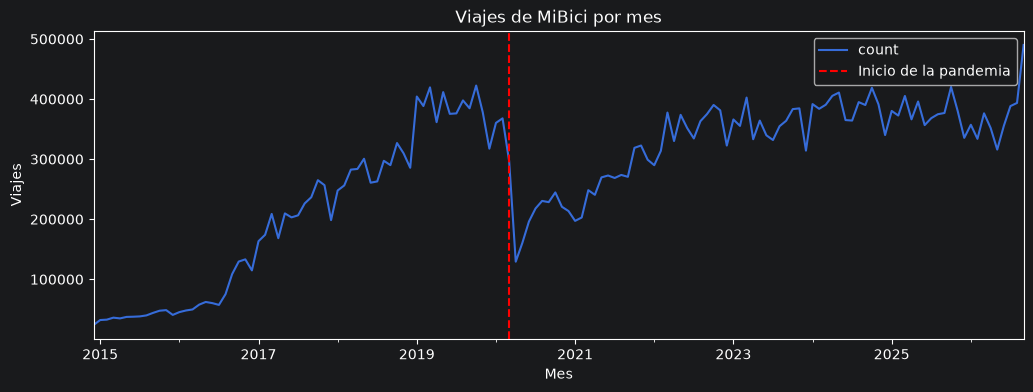

In [12]:
fig, ax = plt.subplots(figsize=(12, 4))
viajes_por_mes.plot(ax=ax)
ax.axvline(pd.Period("2020-03", freq="M"), color="red", linestyle="--", label="Inicio de la pandemia")
ax.set_title("Viajes de MiBici por mes")
ax.set_xlabel("Mes")
ax.set_ylabel("Viajes")
ax.legend()
plt.show()

## 4. Comparar cada mes contra el mismo mes de 2019

La gráfica muestra la forma, pero para justificar el corte necesitamos números. Comparamos cada mes contra **el mismo mes de 2019**, el último año normal antes de la pandemia. Comparar mes contra mismo mes evita confundir la estacionalidad (por ejemplo, diciembre siempre baja) con una caída real.

Primero acomodamos los conteos en una tabla: una fila por año y una columna por mes.

- `pd.DataFrame({...})` arma una tabla con tres columnas: año, mes y viajes.
- `.pivot(index="anio", columns="mes", values="viajes")` la reacomoda: los años quedan como filas y los meses como columnas.

In [13]:
tabla = pd.DataFrame(
    {
        "anio": viajes_por_mes.index.year,
        "mes": viajes_por_mes.index.month,
        "viajes": viajes_por_mes.values,
    }
).pivot(index="anio", columns="mes", values="viajes")
tabla

mes,1,2,3,4,5,6,7,8,9,10,11,12
anio,,,,,,,,,,,,
2014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23967.0
2015,32144.0,32787.0,36096.0,34863.0,37340.0,37647.0,38190.0,39833.0,44000.0,47648.0,48626.0,40697.0
2016,45317.0,48041.0,49766.0,57750.0,62235.0,60300.0,57324.0,75218.0,108558.0,129491.0,133140.0,114778.0
2017,163361.0,174019.0,208794.0,168394.0,209662.0,203015.0,206446.0,226223.0,236560.0,264953.0,256661.0,198446.0
2018,247754.0,256187.0,282550.0,283606.0,300611.0,260743.0,262868.0,297216.0,289979.0,326772.0,309602.0,285597.0
2019,404177.0,388369.0,419452.0,361504.0,411555.0,375353.0,376124.0,397709.0,384649.0,422473.0,377883.0,317404.0
2020,360276.0,367864.0,296759.0,129276.0,160437.0,196071.0,217858.0,230399.0,228383.0,244543.0,220679.0,213527.0
2021,197195.0,202781.0,248294.0,240557.0,269595.0,272721.0,268605.0,273668.0,270554.0,318787.0,322648.0,299005.0
2022,289864.0,313752.0,377505.0,330094.0,373701.0,351595.0,334356.0,363161.0,375014.0,390156.0,381192.0,322552.0


Ahora dividimos cada fila entre la fila de 2019 y multiplicamos por 100. Un valor de `36` significa que ese mes tuvo el 36% de los viajes del mismo mes de 2019; `100` significa que regresó al nivel de 2019.

In [14]:
porcentaje_vs_2019 = (tabla / tabla.loc[2019] * 100).round()
porcentaje_vs_2019.loc[2019:]

mes,1,2,3,4,5,6,7,8,9,10,11,12
anio,,,,,,,,,,,,
2019,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2020,89.0,95.0,71.0,36.0,39.0,52.0,58.0,58.0,59.0,58.0,58.0,67.0
2021,49.0,52.0,59.0,67.0,66.0,73.0,71.0,69.0,70.0,75.0,85.0,94.0
2022,72.0,81.0,90.0,91.0,91.0,94.0,89.0,91.0,97.0,92.0,101.0,102.0
2023,91.0,91.0,96.0,92.0,88.0,90.0,88.0,89.0,95.0,91.0,102.0,99.0
2024,97.0,99.0,93.0,112.0,100.0,97.0,97.0,99.0,101.0,99.0,103.0,107.0
2025,94.0,96.0,97.0,101.0,96.0,95.0,98.0,94.0,98.0,99.0,101.0,106.0
2026,88.0,86.0,90.0,97.0,77.0,95.0,103.0,99.0,127.0,NaN,NaN,NaN


## 5. Últimos meses

Los meses más recientes son los que se usarán para probar los modelos, así que revisamos que no tengan nada raro.

In [15]:
viajes_por_mes["2025-09":]

inicio
2025-09    376789
2025-10    420064
2025-11    380328
2025-12    335420
2026-01    357180
2026-02    333756
2026-03    376243
2026-04    351851
2026-05    315895
2026-06    355303
2026-07    388257
2026-08    393524
2026-09    490056
Freq: M, Name: count, dtype: int64

## 6. Viajes duplicados

La primera versión del Parquet tenía 758 viajes de septiembre de 2026 escritos dos veces (copias exactas, ya venían así en el CSV de MiBici). `dataset.py` ahora los elimina; estas celdas verifican que no quede ningún `viaje_id` repetido en ningún mes. Si aparecen filas aquí, hay un duplicado nuevo que revisar.

Para no gastar memoria leemos solo las columnas necesarias: `viaje_id` para encontrar repetidos e `inicio` para saber de qué mes son (~600 MB en lugar de ~2.2 GB con las 8 columnas).

- `.duplicated(keep=False)` marca **todas** las filas cuyo `viaje_id` aparece más de una vez, el original y la copia. Con el valor por defecto (`keep="first"`) solo marcaría la copia.
- Como se revisa todo el archivo a la vez, también detecta un mismo `viaje_id` repetido en meses distintos.

In [16]:
ids = pd.read_parquet(INTERIM_DATA_DIR / "viajes.parquet", columns=["viaje_id", "inicio"])
repetidos = ids[ids["viaje_id"].duplicated(keep=False)]

print(f"Filas con viaje_id repetido: {len(repetidos):,}")
repetidos["inicio"].dt.to_period("M").value_counts().sort_index()

Filas con viaje_id repetido: 0


Series([], Freq: M, Name: count, dtype: int64)

Que el `viaje_id` se repita no garantiza que toda la fila sea igual. Para comprobarlo hacen falta las 8 columnas, pero solo de las filas repetidas.

- `filters` le pide a Parquet que lea **solo las filas** cuyo `viaje_id` está en la lista: se cargan ~1,500 filas en lugar de 39 millones.
- `.duplicated()` sin argumentos compara **la fila completa**. Si las copias exactas son la mitad de las filas leídas, todas son duplicados exactos.

In [17]:
filas_repetidas = pd.read_parquet(
    INTERIM_DATA_DIR / "viajes.parquet",
    filters=[("viaje_id", "in", repetidos["viaje_id"].unique().tolist())],
)
print(f"Filas leídas: {len(filas_repetidas):,}")
print(f"Copias exactas: {filas_repetidas.duplicated().sum():,}")

Filas leídas: 0
Copias exactas: 0


## 7. Observaciones

- **Antes de la pandemia:** el uso crece de 2015 a 2018 y se estabiliza en 2019, con unos 386 mil viajes al mes en promedio.
- **Pandemia:** en abril de 2020 hubo 129,276 viajes, el 36% de abril de 2019 (361,504). Todos los meses de 2020 y 2021 quedan por debajo de 2019.
- **Recuperación:** enero y febrero de 2022 siguen bajos (72% y 81% de 2019). Desde **marzo de 2022** casi todos los meses están entre 86% y 112% del mismo mes de 2019, es decir, el uso regresó al nivel previo a la pandemia y se mantiene.
- **Estacionalidad:** diciembre baja todos los años. Conviene usar años completos para que el modelo vea cada temporada varias veces.
- **Duplicados:** el CSV de septiembre de 2026 traía 758 viajes escritos dos veces (copias exactas). Ningún otro mes tiene duplicados. Se eliminan en `dataset.py` (ver `references/fuentes_datos.md`).
- **Pendiente de revisar:** septiembre de 2026 tiene 489,298 viajes (127% de 2019), el máximo de toda la serie; mayo de 2026 queda bajo (77%). Hay que confirmar si son datos correctos antes de usarlos para probar los modelos.

**Conclusión preliminar:** los datos de 2020 y 2021 no representan la operación normal. El periodo utilizable empieza en 2022; falta decidir si en enero (años completos) o en marzo (primer mes recuperado).